# 09 · CP4 generalization gate, seed 42: P1 on the development split (P2 waits)

**L4.** Run it after notebook 07 has frozen the development split and notebook 08 has cached the unified probe.

- **P1 dev** (20% of each GenImage validation folder, frozen):
  - the detection model and the detection CLIP probe (G1, RF);
  - the unified model and the unified probe (second row);
  - raw and harmonized files. Real images are scored once, since they are the same in both versions.
- **G1:** detection model mean accuracy > 0.721, and above the probe on raw and on harmonized files.
- **RF:** ≥ 0.98 on every unseen generator → stop and ask.
- **P2:** behind `P2_ENABLED = False` until Dhanush decides on localization.
- **Also reported:** the unified model's false "edited" rate on real images by tile count; published GenImage results for context.

**Result** (send to Claude): `Paper 1/runs/checkpoints/cp4_generalization_gate_seed42.json`. Per-image P1 rows are written to `runs/cp4/p1_dev_seed42.csv`; the accuracy figure (seaborn, PNG + PDF) to `runs/cp4/figures/`. The last cell draws it from the saved report, so it can be redrawn on a CPU runtime: `FIGURES_ONLY = True` in cell 2, then cells 1, 2 and the last.

In [1]:
# Cell 1: mount Drive, get the code, install it
import os, subprocess, sys

DRY = os.environ.get('EVIGROUND_DRY_RUN') == '1'   # CI / local test: fake sources, temp folders
REPO_URL = 'github.com/DHANUSHKUMMARI/Paper1.git'
BRANCH = 'main'                                    # 'claude/nice-curie-3tzxzr' before the merge

if DRY:
    REPO = os.path.abspath('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')
else:
    from google.colab import drive, userdata
    drive.mount('/content/drive')
    REPO = '/content/Paper1'
    if not os.path.exists(REPO):
        try:
            tok = userdata.get('GITHUB_TOKEN')       # never printed
        except Exception:
            tok = None
        url = f'https://{tok}@{REPO_URL}' if tok else f'https://{REPO_URL}'
        r = subprocess.run(['git', 'clone', '--depth', '1', '--branch', BRANCH, url, REPO],
                           capture_output=True, text=True)
        if r.returncode != 0:                        # stderr is not shown: it can contain the URL
            raise RuntimeError('git clone failed: check GITHUB_TOKEN (Secrets panel) and BRANCH')
        subprocess.run(['git', '-C', REPO, 'remote', 'set-url', 'origin', f'https://{REPO_URL}'],
                       check=True)
    else:
        subprocess.run(['git', '-C', REPO, 'pull', '--ff-only'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', REPO + '[train]'], check=True)
    # Colab ships torchao 0.10; peft refuses a torchao older than 0.16 with an ImportError when it
    # adds the LoRA layers, although EviGround never uses torchao: remove an old one.
    import importlib, importlib.metadata as _md
    from packaging.version import Version
    try:
        if Version(_md.version('torchao')) < Version('0.16.0'):
            subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', '-q', 'torchao'], check=True)
            importlib.invalidate_caches()
    except _md.PackageNotFoundError:
        pass

sys.path.insert(0, os.path.join(REPO, 'src'))
# Re-running in a runtime that already imported eviground would keep the OLD code in memory
# although git pulled the new one: drop it so the next import reads the files on disk.
for _name in [m for m in sys.modules if m == 'eviground' or m.startswith('eviground.')]:
    del sys.modules[_name]
print('repo:', REPO, '| branch:', BRANCH, '| dry run:', DRY)

Mounted at /content/drive
repo: /content/Paper1 | branch: main | dry run: False


In [2]:
# Cell 2: settings
DRY_DIR = 'eviground_cp4gate_dry'
PROFILES = ['unified', 'detection']
P2_ENABLED = False   # True only after Dhanush's decision on localization

import csv, datetime, json, logging, os, time
from pathlib import Path
logging.basicConfig(level=logging.INFO, force=True)
import numpy as np, torch
from eviground.config import load_config
from eviground.data import pack
from eviground.env import get_paths, session_info
from eviground.eval import runner

CU_PER_HOUR = 1.94         # read the live rate in Colab's resource panel and update
FIGURES_ONLY = False       # True: only redraw the figures from the saved files (CPU runtime is enough);
                           # then run cells 1, 2 and the last cell, nothing else
SEED = 42
T0 = time.time()
info = session_info(cu_per_hour=CU_PER_HOUR)
paths = get_paths()
if DRY:   # fake world, tiny models, CPU
    import shutil, tempfile
    from eviground.env import Paths
    _dry = Path(tempfile.gettempdir()) / DRY_DIR
    shutil.rmtree(_dry, ignore_errors=True)
    paths = Paths(root=_dry / 'drive' / 'Paper 1', local_data=_dry / 'data')
paths.ensure()
CONFIG = 'debug' if DRY else 'base'
HF_CACHE = paths.cache / 'hf' if DRY else Path('/content/hf_cache')
OVERRIDES = [f'model.semantic.cache_dir={HF_CACHE}', f'compute.cu_per_hour={CU_PER_HOUR}']
cfg = load_config(CONFIG, OVERRIDES)
if not DRY and not FIGURES_ONLY:
    assert torch.cuda.is_available(), 'needs a GPU runtime (L4); or set FIGURES_ONLY = True to redraw figures'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EXPERIMENT = cfg.get('experiment', 'eviground')
CK = paths.runs / 'checkpoints'
OUT = paths.runs / 'cp4'
PROBES = OUT / 'probes'
PROBE_EPOCHS = 1 if DRY else 3
WORKERS = 0 if DRY else int(cfg.data.num_workers)
BATCH = 8 if DRY else 64
run_dir = lambda profile: paths.runs / f'{EXPERIMENT}_{profile}_seed{SEED}'
OUT.mkdir(parents=True, exist_ok=True); PROBES.mkdir(parents=True, exist_ok=True)
print('commit', info['git_commit'], '| gpu', info.get('gpu_name'), '| device', DEVICE)

INFO:eviground.env:session: python 3.13.16 | torch 2.14.1+cu130 | gpu NVIDIA L4 (23.7 GB) | drive mounted=True free=114.8 GB | commit 616bec5 | CU/h 1.94


commit 616bec5 | gpu NVIDIA L4 | device cuda


In [3]:
# Cell 3: shards (dry run: fake world and tiny trained models)

assert not FIGURES_ONLY, 'FIGURES_ONLY = True: run only cells 1, 2 and the last cell (the figures)'
SHARDS = paths.shards
CP1_RESULT = None
if DRY:   # fake world -> CP1 -> shards -> tiny trained models (one epoch each)
    from eviground.data.cp1 import CP1Config, run_cp1
    from eviground.data.download import ensure_data
    from eviground.data.fake_cp1 import cp1_overrides, make_cp1_world
    from eviground.train.trainer import Trainer
    sources = make_cp1_world(paths.datasets, paths.root.parent / 'fake_remote', coco_images=40)
    ensure_data('cp1', paths=paths, sources=sources, stage_local=True, overrides=cp1_overrides(40))
    CP1_RESULT = run_cp1(paths, CP1Config(workers=2, crops_per_class=60, blockiness_per_group=20,
                                          base_unclear_max=0.2, diffseg_card_splits={'train': 18, 'validation': 12}),
                         out_dir=CK / 'cp1', cache_dir=paths.cache / 'cp1', progress=None)
    pack.pack(CK / 'cp1' / 'manifest_cp1.csv.gz', SHARDS, free_bytes=10**12, margin=0,
              shard_bytes=200_000, sample_per_source=5, progress=None)
    for profile in PROFILES:
        Trainer(load_config(CONFIG, OVERRIDES + ['train.epochs=1']), SHARDS, run_dir(profile),
                seed=SEED, profile=profile, resume=None, log=None).fit()
LOCAL_SHARDS = paths.local_data / 'shards'
print(pack.stage_shards(SHARDS, LOCAL_SHARDS, progress=print))
SHARDS = LOCAL_SHARDS

INFO:numexpr.utils:NumExpr defaulting to 12 threads.


staging 18 of 18 shards (15.75 GB) to /content/data/shards
  1/18 coco/shard-00000.tar: 0.96 GB, 48 s
  2/18 diffseg30k/shard-00000.tar: 0.59 GB, 68 s
  3/18 diffseg30k/shard-00001.tar: 1.28 GB, 106 s
  4/18 diffseg30k/shard-00002.tar: 0.88 GB, 133 s
  5/18 diffseg30k/shard-00003.tar: 0.10 GB, 140 s
  6/18 genimage/shard-00000.tar: 1.07 GB, 169 s
  7/18 genimage/shard-00001.tar: 1.02 GB, 198 s
  8/18 genimage/shard-00002.tar: 1.02 GB, 230 s
  9/18 genimage/shard-00003.tar: 1.00 GB, 259 s
  10/18 genimage/shard-00004.tar: 1.01 GB, 289 s
  11/18 genimage/shard-00005.tar: 1.07 GB, 322 s
  12/18 genimage/shard-00006.tar: 0.90 GB, 349 s
  13/18 genimage/shard-00007.tar: 0.94 GB, 373 s
  14/18 genimage/shard-00008.tar: 0.90 GB, 395 s
  15/18 genimage/shard-00009.tar: 0.91 GB, 424 s
  16/18 genimage/shard-00010.tar: 0.17 GB, 435 s
  17/18 sidset/shard-00000.tar: 0.94 GB, 457 s
  18/18 sidset/shard-00001.tar: 1.00 GB, 483 s
{'local_dir': '/content/data/shards', 'shards': 18, 'copied': 18, 'ski

In [4]:
# Cell 4: the frozen development split, the manifest and the GenImage quality distribution
from eviground.data import harmonize
from eviground.data.cp1 import _read_csv_gz
from eviground.eval import devsplit, testsets
MANIFEST = _read_csv_gz(CK / 'cp1' / 'manifest_cp1.csv.gz')
if DRY:   # the fake world has 2 images per folder: a larger fraction so something is scored
    SPLIT = devsplit.build_dev_split(MANIFEST, fraction=0.5)
    table = CP1_RESULT['quality_distribution_genimage_real']['table']
else:
    SPLIT = devsplit.load(CK / 'cp4_dev_split.json')
    assert devsplit.verify(SPLIT, MANIFEST)['same'], 'the frozen dev split does not match the manifest'
    table = json.loads((CK / 'cp1_data_integrity.json').read_text())['result']['quality_distribution_genimage_real']['table']
DIST = harmonize.QualityDistribution.from_dict(table)
P1_ROWS = testsets.dev_rows(MANIFEST, SPLIT['dev_uids'], 'test_P1')
t = time.time()
P1_ROWS = testsets.stage_files(P1_ROWS, paths.local_data / 'p1_dev')
STAGE_MIN = round((time.time() - t) / 60, 2)
print(len(P1_ROWS), 'P1 dev images staged in', STAGE_MIN, 'min | split', SPLIT['dev_sha256'][:12])

20000 P1 dev images staged in 19.08 min | split 1e0792a8f474


In [5]:
# Cell 5: models and probes

from eviground.baselines import clip_probe

def get_probe(profile, model):
    '''The cached probe of ``profile``, or train it (the model's frozen CLIP, LoRA off).'''
    path = PROBES / f'probe_{profile}.pt'
    if path.is_file():
        saved = torch.load(path, weights_only=True)
        print('probe reused:', path)
        return clip_probe.ProbeHead.from_state(saved['head']).to(DEVICE), saved['report']
    tc = dict(cfg.train)
    crops = int((tc.get('detection') or {}).get('crops_per_epoch', 16000)) if profile == 'detection' else int(tc['crops_per_epoch'])
    train_b, val_b = runner.probe_data(SHARDS, profile=profile, crop=int(cfg.data.crop),
                                       crops_per_epoch=crops, epochs=PROBE_EPOCHS, seed=SEED,
                                       batch=BATCH, workers=WORKERS, augment_cfg=cfg.data.get('augment'))
    t = time.time()
    head, report = clip_probe.train_probes(model, train_b(), val_b, profile=profile, device=DEVICE)
    report['minutes'] = round((time.time() - t) / 60, 2)
    torch.save({'head': head.state(), 'report': report}, path)
    return head.to(DEVICE), report

MODELS, HEADS, PROBE_REPORTS = {}, {}, {}
for profile in PROFILES:
    MODELS[profile] = runner.load_trained(cfg.model, run_dir(profile) / 'best.pt', DEVICE)
    HEADS[profile], PROBE_REPORTS[profile] = get_probe(profile, MODELS[profile])
print({p: r.get('class_token') for p, r in PROBE_REPORTS.items()})

INFO:httpx:HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/openai/clip-vit-large-patch14/resolve/32bd64288804d66eefd0ccbe215aa642df71cc41/model.safetensors "HTTP/1.1 302 Found"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/models/openai/clip-vit-large-patch14/xet-read-token/32bd64288804d66eefd0ccbe215aa642df71cc41 "HTTP/1.1 200 OK"


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

INFO:httpx:HTTP Request: HEAD https://huggingface.co/openai/clip-vit-large-patch14/resolve/32bd64288804d66eefd0ccbe215aa642df71cc41/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/openai/clip-vit-large-patch14/32bd64288804d66eefd0ccbe215aa642df71cc41/config.json?%2Fopenai%2Fclip-vit-large-patch14%2Fresolve%2F32bd64288804d66eefd0ccbe215aa642df71cc41%2Fconfig.json=&etag=%222c19f6666e0e163c7954df66cb901353fcad088e%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: GET https://huggingface.co/api/resolve-cache/models/openai/clip-vit-large-patch14/32bd64288804d66eefd0ccbe215aa642df71cc41/config.json?%2Fopenai%2Fclip-vit-large-patch14%2Fresolve%2F32bd64288804d66eefd0ccbe215aa642df71cc41%2Fconfig.json=&etag=%222c19f6666e0e163c7954df66cb901353fcad088e%22 "HTTP/1.1 200 OK"


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

... (4 outputs left out)

probe reused: /content/drive/MyDrive/Paper 1/runs/cp4/probes/probe_unified.pt


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: /content/hf_cache/models--openai--clip-vit-large-patch14/snapshots/32bd64288804d66eefd0ccbe215aa642df71cc41
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.final_layer_norm.bias                             | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_no

probe detection: {'profile': 'detection', 'train_crops': 48000, 'val_crops': 7590, 'class_token': {'l2': 0.001, 'val_auc': 0.9965114095622302, 'tried': [{'l2': 0.0001, 'val_auc': 0.9964066251330431}, {'l2': 0.001, 'val_auc': 0.9965114095622302}, {'l2': 0.01, 'val_auc': 0.9962352799634556}, {'l2': 0.1, 'val_auc': 0.9932601680408047}, {'l2': 1.0, 'val_auc': 0.9831725605993419}, {'l2': 10.0, 'val_auc': 0.9657592335099073}]}}
{'unified': {'l2': 0.001, 'val_auc': 0.9784117913657092, 'tried': [{'l2': 0.0001, 'val_auc': 0.978389652883289}, {'l2': 0.001, 'val_auc': 0.9784117913657092}, {'l2': 0.01, 'val_auc': 0.9770548317170725}, {'l2': 0.1, 'val_auc': 0.9682918171962043}, {'l2': 1.0, 'val_auc': 0.9458829955606592}, {'l2': 10.0, 'val_auc': 0.908276168547185}]}, 'detection': {'l2': 0.001, 'val_auc': 0.9965114095622302, 'tried': [{'l2': 0.0001, 'val_auc': 0.9964066251330431}, {'l2': 0.001, 'val_auc': 0.9965114095622302}, {'l2': 0.01, 'val_auc': 0.9962352799634556}, {'l2': 0.1, 'val_auc': 0.99326

In [6]:
# Cell 6: P1 dev, raw and harmonized (real images once)
RECORDS, STATS = [], {}
real_rows = [r for r in P1_ROWS if r['label'] == 'real']
gen_rows = [r for r in P1_ROWS if r['label'] == 'generated']
for profile in PROFILES:
    predict = runner.joint_predictor(MODELS[profile], HEADS[profile], DEVICE)
    names = {'model': profile, 'probe': f'{profile}_probe'}
    for version, rows in (('raw', P1_ROWS), ('harmonized', gen_rows)):
        recs, STATS[f'{profile}/{version}'] = runner.p1_pass(
            predict, testsets.file_items(rows, version=version, dist=DIST), DEVICE, names, version)
        RECORDS += recs
        print(profile, version, STATS[f'{profile}/{version}'])
# the real images are the same files in both versions
RECORDS += [{**r, 'version': 'harmonized'} for r in RECORDS if r['version'] == 'raw' and r['label'] == 'real']
with open(OUT / 'p1_dev_seed42.csv', 'w', newline='') as fh:
    w = csv.DictWriter(fh, fieldnames=list(RECORDS[0]))
    w.writeheader(); w.writerows(RECORDS)

unified raw {'images': 20000, 'tiles': 88347, 'max_tiles': 204, 'seconds': 963.9}
unified harmonized {'images': 10000, 'tiles': 40000, 'max_tiles': 16, 'seconds': 515.6}
detection raw {'images': 20000, 'tiles': 88347, 'max_tiles': 204, 'seconds': 958.5}
detection harmonized {'images': 10000, 'tiles': 40000, 'max_tiles': 16, 'seconds': 514.6}


In [7]:
# Cell 7: P2 dev (only after Dhanush's decision)
P2 = None
if P2_ENABLED:
    from eviground.data.download import ensure_data
    if not DRY:
        ensure_data(datasets=['diffseg30k'], paths=paths, stage_local=True)
    p2_rows = testsets.dev_rows(MANIFEST, SPLIT['dev_uids'], 'test_P2')
    predict = runner.joint_predictor(MODELS['unified'], HEADS['unified'], DEVICE)
    P2_DIAG = runner.diagnosis_pass(predict, testsets.file_items(p2_rows), DEVICE, ceilings=False, sweep=False)
    P2 = {'model': runner.p2_summary(P2_DIAG['edited'], 'model'),
          'probe': runner.p2_summary(P2_DIAG['edited'], 'probe'), 'pass': P2_DIAG['stats']}
    print(json.dumps(P2['model']['all'], indent=1, default=str))
else:
    print('P2 not scored (P2_ENABLED = False)')

P2 not scored (P2_ENABLED = False)


In [8]:
# Cell 8: the CP4 evaluation and its result file
from eviground.eval import cp4
TABLE = cp4.p1_table(RECORDS)
hours = (time.time() - T0) / 3600
REPORT = cp4.evaluate(TABLE, model='detection', probe='detection_probe',
                      p2=None if P2 is None else P2['model']['all'],
                      extra={
    'step': 'CP4 generalization gate (development split)', 'dry_run': DRY, 'branch': BRANCH, 'seed': SEED,
    'session': info, 'dev_split': devsplit.summary(SPLIT), 'probes': PROBE_REPORTS,
    'false_edited_unified_p1_real': cp4.false_edited(RECORDS, 'unified'),
    'p2': P2, 'stats': STATS, 'staging_minutes': STAGE_MIN,
    'utc': datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds'),
    'wall_time_h': round(hours, 3), 'cu_per_hour': CU_PER_HOUR, 'compute_units': round(hours * CU_PER_HOUR, 2),
})
out = cp4.write_report(REPORT, CK / 'cp4_generalization_gate_seed42.json')
for name, c in REPORT['checks'].items():
    print(f'{name:3} {c["status"]:13}', {k: v for k, v in c.items() if k != 'status'})
for head, versions in TABLE.items():
    print(head, {v: round(t['mean_acc'], 4) for v, t in versions.items()})
print('script verdict:', REPORT['verdict'], '| CU', REPORT['compute_units'], '| saved', out)

G1  FAIL          {'bar': 0.721, 'mean_acc': {'raw': {'model': 0.7846093749999999, 'probe': 0.8136458333333333}, 'harmonized': {'model': 0.7770703125, 'probe': 0.8015494791666666}}}
RF  PASS          {'bar': 0.98, 'unseen_acc': {'adm': 0.5591666666666667, 'biggan': 0.70875, 'glide': 0.6220833333333333, 'midjourney': 0.7341666666666666, 'sd15': 0.996875, 'vqdm': 0.6758333333333333, 'wukong': 0.98125}, 'raised': False}
G2  NOT_RUN       {'bar': 0.8, 'note': 'held until Dhanush decides'}
detection {'harmonized': 0.7771, 'raw': 0.7846}
detection_probe {'harmonized': 0.8015, 'raw': 0.8136}
unified {'harmonized': 0.8642, 'raw': 0.881}
unified_probe {'harmonized': 0.8777, 'raw': 0.8953}
script verdict: FAIL | CU 2.73 | saved /content/drive/MyDrive/Paper 1/runs/checkpoints/cp4_generalization_gate_seed42.json


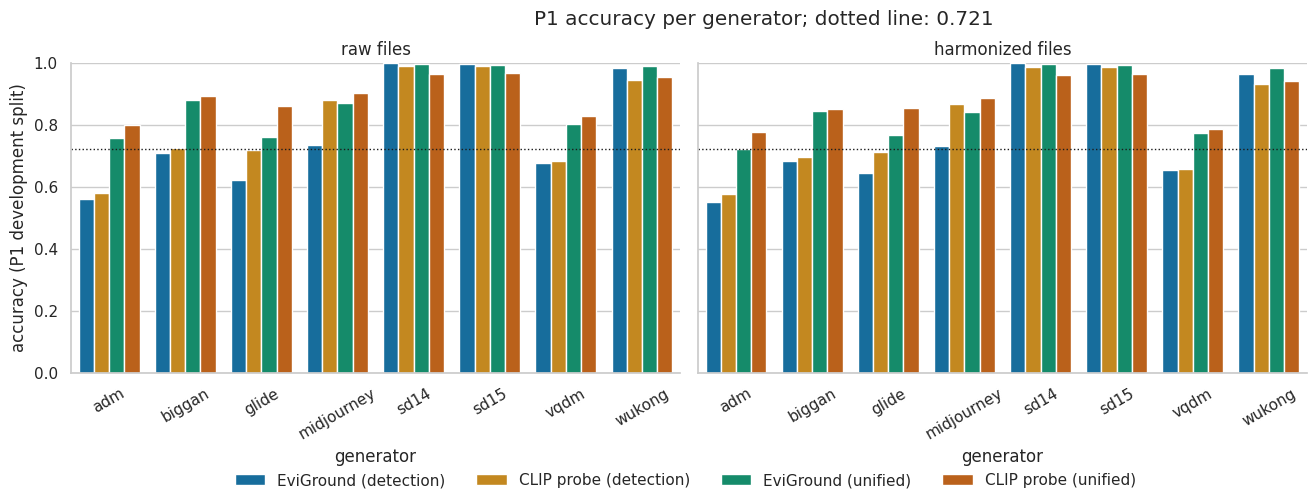

figure (PNG + PDF): /content/drive/MyDrive/Paper 1/runs/cp4/figures/p1_dev_accuracy_seed42.png


In [9]:
# Cell 9: figure (seaborn), drawn from the saved report only
# To redraw it later without the GPU: a CPU runtime, FIGURES_ONLY = True in cell 2, then cells 1, 2 and this one.
from eviground import viz
saved_report = json.loads((CK / 'cp4_generalization_gate_seed42.json').read_text())
FIG = viz.p1_figure(saved_report['p1'], OUT / 'figures', seed=SEED)
print('figure (PNG + PDF):', FIG)
if DRY:
    assert FIG is not None and FIG.is_file(), FIG